# Part 1

# 1. Importation des bibliothèques

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

import time
import os

print("Bibliothèques importées avec succès.")


Bibliothèques importées avec succès.


# 2. Chargement des données

In [3]:
fish = pd.read_csv(
    "../data/raw/2_fish_information.txt",
    sep="\t"
)

environment = pd.read_csv(
    "../data/raw/1_stream_information.txt",
    sep="\t"
)

print("Données des poissons :", fish.shape)
print("Données environnementales :", environment.shape)


Données des poissons : (12288, 9)
Données environnementales : (118, 17)


In [4]:

# Dimensions des datasets
print("FISH DATASET")
print(fish.shape)

print("\nENVIRONMENT DATASET")
print(environment.shape)

# Informations générales
print("\nFISH INFORMATION")
fish.info()

print("\nENVIRONMENT INFORMATION")
environment.info()


FISH DATASET
(12288, 9)

ENVIRONMENT DATASET
(118, 17)

FISH INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 12288 entries, 0 to 12287
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Code_ID          12288 non-null  int64  
 1   Stream           12288 non-null  str    
 2   Location         12288 non-null  str    
 3   Family           12288 non-null  str    
 4   Genus            12288 non-null  str    
 5   Species          12288 non-null  str    
 6   Scientific_name  12288 non-null  str    
 7   Length_mm        12288 non-null  int64  
 8   Mass_g           12288 non-null  float64
dtypes: float64(1), int64(2), str(6)
memory usage: 864.1 KB

ENVIRONMENT INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Code_ID              118 non-null    int

In [5]:

print("FISH DATASET")
display(fish.head())

print("ENVIRONMENT DATASET")
display(environment.head())

FISH DATASET


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g
0,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,442,1700.0
1,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,405,1220.0
2,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,373,1040.0
3,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,199,139.9
4,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,225,133.0


ENVIRONMENT DATASET


,Code_ID,Stream,Location,Lat_degree,Long_degree,Source,Day,Month,Year,Fish_number,SA_m2,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
0,1,Ebro,Miranda de Ebro,42.687282,-2.954187,CHE,18,10,2007,74,698.0,0.10,8.38,12.5,727,454.68,2.00
1,2,Arga,Funes,42.301003,-1.789143,CHE,8,7,2007,143,415.0,0.24,10.93,13.6,576,279.10,10.50
2,3,Aragon,Caparroso,42.344712,-1.650659,CHE,27,8,2007,70,575.0,0.10,8.35,13.4,625,300.01,10.65
3,4,Martin,Hijar,41.173897,-0.456685,CHE,25,10,2007,68,358.0,0.13,13.10,14.6,371,294.61,10.75
4,5,Guadalope,Alcaniz,40.932767,-0.196697,CHE,24,10,2006,54,887.0,0.11,10.33,14.3,431,383.92,10.25


# 3. Data Quality Assessment

In [6]:

# 1. Valeurs manquantes
print("MISSING VALUES - FISH")
print(fish.isnull().sum())

print("\nMISSING VALUES - ENVIRONMENT")
print(environment.isnull().sum())


# 2. Doublons
print("\nDUPLICATES")
print("Fish duplicates:", fish.duplicated().sum())
print("Environment duplicates:", environment.duplicated().sum())


# 3. Vérification des valeurs anormales
print("\nANOMALOUS VALUES")

print("Length <= 0:", (fish["Length_mm"] <= 0).sum())
print("Mass <= 0:", (fish["Mass_g"] <= 0).sum())

print("\nNegative environmental values:")
print(environment.select_dtypes(include="number").lt(0).sum())


# 4. Statistiques descriptives
print("\nFISH STATISTICS")
display(fish[["Length_mm", "Mass_g"]].describe())

print("\nENVIRONMENT STATISTICS")
display(environment.describe())


MISSING VALUES - FISH
Code_ID            0
Stream             0
Location           0
Family             0
Genus              0
Species            0
Scientific_name    0
Length_mm          0
Mass_g             0
dtype: int64

MISSING VALUES - ENVIRONMENT
Code_ID                0
Stream                 0
Location               0
Lat_degree             0
Long_degree            0
Source                 0
Day                    0
Month                  0
Year                   0
Fish_number            0
SA_m2                  0
TP_mg.l                0
TN_mg.l                0
Temp_degree_celcius    0
Prec_mm                0
Alt_m                  0
IMPRESS                0
dtype: int64

DUPLICATES
Fish duplicates: 883
Environment duplicates: 0

ANOMALOUS VALUES
Length <= 0: 0
Mass <= 0: 0

Negative environmental values:
Code_ID                 0
Lat_degree              0
Long_degree            78
Day                     0
Month                   0
Year                    0
Fish_number    

,Length_mm,Mass_g
count,12288.000000,12288.000000
mean,99.342855,45.725521
std,74.036214,180.627982
min,15.000000,0.100000
25%,56.000000,2.000000
50%,77.000000,5.600000
75%,115.000000,18.925000
max,862.000000,4500.000000



ENVIRONMENT STATISTICS


,Code_ID,Lat_degree,Long_degree,Day,Month,Year,Fish_number,SA_m2,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
count,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000,118.000000
mean,59.500000,42.055141,-0.831358,18.491525,8.000000,2006.576271,104.135593,623.674746,0.218814,8.320847,12.607627,643.889831,491.848559,6.615339
std,34.207699,0.650876,1.625390,7.742375,1.389829,1.560226,54.331511,272.607717,0.397449,8.285272,1.863282,193.662663,237.549998,3.434911
min,1.000000,40.734957,-4.166169,1.000000,5.000000,2003.000000,34.000000,72.000000,0.050000,0.500000,6.900000,349.000000,86.210000,0.410000
25%,30.250000,41.586605,-1.919367,12.000000,7.000000,2007.000000,59.500000,468.250000,0.100000,2.202500,11.625000,490.750000,299.792500,3.750000
50%,59.500000,42.196885,-0.793998,20.000000,7.000000,2007.000000,91.000000,622.000000,0.100000,6.040000,12.800000,600.500000,465.345000,7.200000
75%,88.750000,42.582703,0.223580,25.000000,9.750000,2007.000000,139.750000,759.250000,0.177500,12.170000,13.775000,770.000000,636.652500,10.075000
max,118.000000,43.083843,2.293824,30.000000,10.000000,2009.000000,263.000000,2000.000000,3.160000,60.240000,16.400000,1175.000000,1293.660000,12.000000


In [7]:

# Extract exact duplicate rows
fish_duplicates = fish[fish.duplicated(keep=False)]

print("Total duplicate rows:", len(fish_duplicates))

# Display some duplicate rows
display(fish_duplicates.head(20))

# Number of duplicate rows by species
print("\nDuplicates by species:")
display(
    fish_duplicates["Scientific_name"]
    .value_counts()
    .head(10)
)


Total duplicate rows: 1565


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g
29,1,Ebro,Miranda de Ebro,Cyprinidae,Gobio,lozanoi,Gobio lozanoi,75,5.8
30,1,Ebro,Miranda de Ebro,Cyprinidae,Gobio,lozanoi,Gobio lozanoi,75,5.8
31,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,78,5.7
32,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,78,5.7
53,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,62,2.9
54,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,62,2.9
68,1,Ebro,Miranda de Ebro,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,39,0.6
69,1,Ebro,Miranda de Ebro,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,39,0.6
74,2,Arga,Funes,Leuciscidae,Phoxinus,phoxinus,Phoxinus phoxinus,32,0.3
79,2,Arga,Funes,Leuciscidae,Achondrostoma,arcasii,Achondrostoma arcasii,28,0.2



Duplicates by species:


Scientific_name
Phoxinus phoxinus          449
Parachondrostoma miegii    268
Barbatula quignardi        153
Gobio lozanoi              141
Barbus haasi               106
Luciobarbus graellsii       89
Salmo trutta                59
Alburnus alburnus           55
Gambusia holbrooki          55
Cobitis calderoni           48
Name: count, dtype: int64

In [8]:

fish_ids = set(fish["Code_ID"])
environment_ids = set(environment["Code_ID"])

print("Unique fish site IDs:", len(fish_ids))
print("Unique environment site IDs:", len(environment_ids))

print("IDs missing in environment:", fish_ids - environment_ids)
print("IDs missing in fish:", environment_ids - fish_ids)


Unique fish site IDs: 118
Unique environment site IDs: 118
IDs missing in environment: set()
IDs missing in fish: set()


# 4. Data Integration

In [ ]:

# Remove redundant columns from the environmental dataset
environment_clean = environment.drop(
    columns=["Stream", "Location"]
)

# Merge fish and environmental data
df = fish.merge(
    environment_clean,
    on="Code_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verify the merge
print("Merged dataset shape:", df.shape)

print("\nMerge verification:")
print(df["_merge"].value_counts())

# Remove the technical merge indicator
df = df.drop(columns=["_merge"])

print("\nFinal dataset shape:", df.shape)
display(df.head())


Merged dataset shape: (12288, 24)

Merge verification:
_merge
both          12288
left_only         0
right_only        0
Name: count, dtype: int64

Final dataset shape: (12288, 23)


,Code_ID,Stream,Location,Family,Genus,Species,Scientific_name,Length_mm,Mass_g,Lat_degree,...,Month,Year,Fish_number,SA_m2,TP_mg.l,TN_mg.l,Temp_degree_celcius,Prec_mm,Alt_m,IMPRESS
0,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,442,1700.0,42.687282,...,10,2007,74,698.0,0.1,8.38,12.5,727,454.68,2.0
1,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,405,1220.0,42.687282,...,10,2007,74,698.0,0.1,8.38,12.5,727,454.68,2.0
2,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,373,1040.0,42.687282,...,10,2007,74,698.0,0.1,8.38,12.5,727,454.68,2.0
3,1,Ebro,Miranda de Ebro,Cyprinidae,Cyprinus,carpio,Cyprinus carpio,199,139.9,42.687282,...,10,2007,74,698.0,0.1,8.38,12.5,727,454.68,2.0
4,1,Ebro,Miranda de Ebro,Cyprinidae,Luciobarbus,graellsii,Luciobarbus graellsii,225,133.0,42.687282,...,10,2007,74,698.0,0.1,8.38,12.5,727,454.68,2.0


In [ ]:

# Create morphological features
df["ln_length"] = np.log(df["Length_mm"])
df["ln_mass"] = np.log(df["Mass_g"])

# Calculate condition factor
df["condition_factor"] = (
    df["Mass_g"] / (df["Length_mm"] ** 3)
)

# Select the 9 features required for DBSCAN
feature_columns = [
    "ln_length",
    "ln_mass",
    "condition_factor",
    "Temp_degree_celcius",
    "Prec_mm",
    "Alt_m",
    "TP_mg.l",
    "TN_mg.l",
    "IMPRESS"
]

X = df[feature_columns].copy()

# Keep species and site IDs separately for evaluation
species = df["Species"].copy()
site_ids = df["Code_ID"].copy()

# Display results
print("Feature matrix shape:", X.shape)

print("\nSelected features:")
display(X.head())

print("\nMissing values:")
print(X.isnull().sum())

print("\nFeature statistics:")
display(X.describe())


Feature matrix shape: (12288, 9)

Selected features:


,ln_length,ln_mass,condition_factor,Temp_degree_celcius,Prec_mm,Alt_m,TP_mg.l,TN_mg.l,IMPRESS
0,6.091310,7.438384,0.000020,12.5,727,454.68,0.1,8.38,2.0
1,6.003887,7.106606,0.000018,12.5,727,454.68,0.1,8.38,2.0
2,5.921578,6.946976,0.000020,12.5,727,454.68,0.1,8.38,2.0
3,5.293305,4.940928,0.000018,12.5,727,454.68,0.1,8.38,2.0
4,5.416100,4.890349,0.000012,12.5,727,454.68,0.1,8.38,2.0



Missing values:
ln_length              0
ln_mass                0
condition_factor       0
Temp_degree_celcius    0
Prec_mm                0
Alt_m                  0
TP_mg.l                0
TN_mg.l                0
IMPRESS                0
dtype: int64

Feature statistics:


,ln_length,ln_mass,condition_factor,Temp_degree_celcius,Prec_mm,Alt_m,TP_mg.l,TN_mg.l,IMPRESS
count,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000,12288.000000
mean,4.415312,1.869214,0.000012,12.684774,634.870687,483.779501,0.185877,8.667321,6.920002
std,0.571988,1.807121,0.000003,1.679748,188.147054,211.172105,0.341485,9.585847,3.183545
min,2.708050,-2.302585,0.000001,6.900000,349.000000,86.210000,0.050000,0.500000,0.410000
25%,4.025352,0.693147,0.000010,11.700000,490.000000,322.840000,0.090000,2.200000,3.830000
50%,4.343805,1.722767,0.000012,12.900000,581.000000,470.930000,0.100000,5.580000,7.500000
75%,4.744932,2.940481,0.000013,13.700000,767.000000,613.290000,0.140000,12.350000,10.000000
max,6.759255,8.411833,0.000040,16.400000,1175.000000,1293.660000,3.160000,60.240000,12.000000


In [ ]:

# Initialize the scaler
scaler = StandardScaler()

# Standardize the features
X_scaled = scaler.fit_transform(X)

# Convert the result into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

# Display results
print("Standardized matrix shape:", X_scaled.shape)

print("\nMeans after standardization:")
print(X_scaled.mean().round(4))

print("\nStandard deviations after standardization:")
print(X_scaled.std().round(4))

display(X_scaled.head())


Standardized matrix shape: (12288, 9)

Means after standardization:
ln_length             -0.0
ln_mass               -0.0
condition_factor       0.0
Temp_degree_celcius   -0.0
Prec_mm               -0.0
Alt_m                 -0.0
TP_mg.l               -0.0
TN_mg.l                0.0
IMPRESS               -0.0
dtype: float64

Standard deviations after standardization:
ln_length              1.0
ln_mass                1.0
condition_factor       1.0
Temp_degree_celcius    1.0
Prec_mm                1.0
Alt_m                  1.0
TP_mg.l                1.0
TN_mg.l                1.0
IMPRESS                1.0
dtype: float64


,ln_length,ln_mass,condition_factor,Temp_degree_celcius,Prec_mm,Alt_m,TP_mg.l,TN_mg.l,IMPRESS
0,2.930244,3.081917,2.458942,-0.110005,0.489686,-0.137806,-0.251492,-0.029975,-1.545511
1,2.777398,2.898315,2.039744,-0.110005,0.489686,-0.137806,-0.251492,-0.029975,-1.545511
2,2.633493,2.809977,2.570976,-0.110005,0.489686,-0.137806,-0.251492,-0.029975,-1.545511
3,1.535046,1.699853,1.845452,-0.110005,0.489686,-0.137806,-0.251492,-0.029975,-1.545511
4,1.749736,1.671863,-0.081336,-0.110005,0.489686,-0.137806,-0.251492,-0.029975,-1.545511


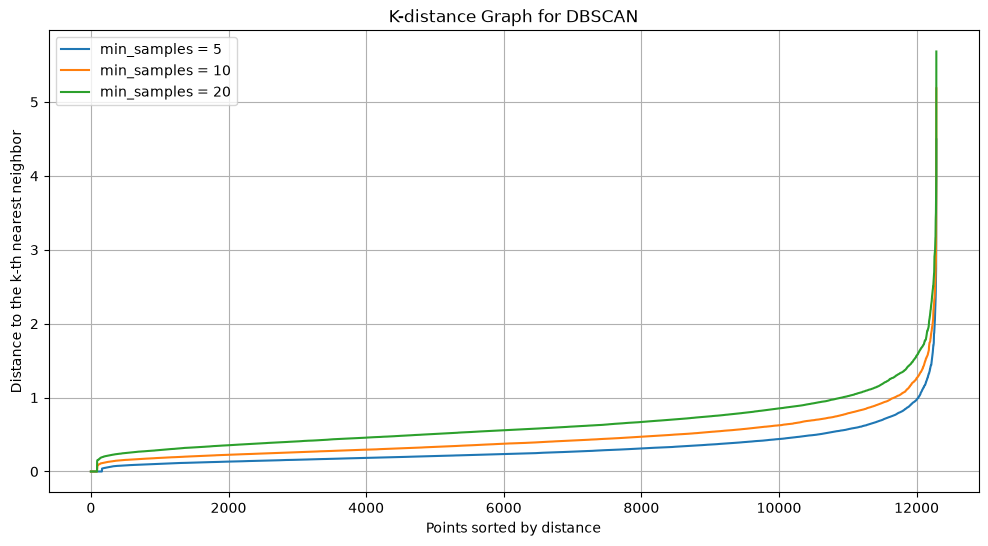

In [ ]:

from sklearn.neighbors import NearestNeighbors

# Values of min_samples specified in the assignment
min_samples_values = [5, 10, 20]

# Calculate nearest-neighbor distances
neighbors = NearestNeighbors(
    n_neighbors=max(min_samples_values),
    metric="euclidean"
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Plot the k-distance curves
plt.figure(figsize=(12, 6))

for k in min_samples_values:
    k_distances = np.sort(distances[:, k - 1])
    
    plt.plot(
        k_distances,
        label=f"min_samples = {k}"
    )

plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to the k-th nearest neighbor")
plt.title("K-distance Graph for DBSCAN")
plt.legend()
plt.grid(True)
plt.show()


In [27]:

from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import DBSCAN
import time

eps_values = [0.3, 0.5, 0.8, 1.2]
min_samples_values = [5, 10, 20]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        start_time = time.time()

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = model.fit_predict(X_scaled)

        elapsed_time = time.time() - start_time

        # Exclude noise points for internal metrics
        non_noise_mask = labels != -1
        X_non_noise = X_scaled.loc[non_noise_mask]
        labels_non_noise = labels[non_noise_mask]

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_percentage = (labels == -1).mean() * 100

        # Calculate metrics only when at least two clusters exist
        if n_clusters >= 2 and len(labels_non_noise) > n_clusters:
            silhouette = silhouette_score(
                X_non_noise,
                labels_non_noise,
                sample_size=min(5000, len(labels_non_noise)),
                random_state=42
            )

            db_index = davies_bouldin_score(
                X_non_noise,
                labels_non_noise
            )
        else:
            silhouette = np.nan
            db_index = np.nan

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_percentage": noise_percentage,
            "silhouette": silhouette,
            "davies_bouldin": db_index,
            "time_seconds": elapsed_time
        })

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)


,eps,min_samples,n_clusters,noise_percentage,silhouette,davies_bouldin,time_seconds
0,0.3,5,306,25.4883,0.2685,0.8986,1.8880
1,0.3,10,163,48.5677,0.4169,0.7508,1.7081
2,0.3,20,45,80.9163,0.6076,0.5299,1.7165
3,0.5,5,179,8.0892,0.1010,1.2146,3.0483
4,0.5,10,145,16.8132,0.1943,1.1566,3.1196
5,0.5,20,99,39.1113,0.3130,1.0093,2.7471
6,0.8,5,77,2.3926,-0.0325,1.2170,5.5186
7,0.8,10,65,4.4189,-0.0099,1.2995,5.7179
8,0.8,20,63,9.3587,0.0118,1.1924,6.1212
9,1.2,5,24,0.6999,-0.1805,0.9519,9.4092


In [ ]:

cluster_sizes = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = model.fit_predict(X_scaled)

        # Count observations in each cluster, excluding noise
        sizes = pd.Series(labels[labels != -1]).value_counts()

        cluster_sizes.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": len(sizes),
            "small_clusters (<10)": (sizes < 10).sum(),
            "medium_clusters (10-49)": (
                ((sizes >= 10) & (sizes < 50)).sum()
            ),
            "large_clusters (>=50)": (sizes >= 50).sum(),
            "smallest_cluster": sizes.min() if len(sizes) else 0,
            "median_cluster_size": sizes.median() if len(sizes) else 0,
            "largest_cluster": sizes.max() if len(sizes) else 0
        })

cluster_sizes_df = pd.DataFrame(cluster_sizes)

display(cluster_sizes_df)


,eps,min_samples,n_clusters,small_clusters (<10),medium_clusters (10-49),large_clusters (>=50),smallest_cluster,median_cluster_size,largest_cluster
0,0.3,5,306,125,125,56,3,15.0,213
1,0.3,10,163,5,119,39,5,26.0,206
2,0.3,20,45,0,26,19,20,41.0,158
3,0.5,5,179,36,74,69,5,35.0,627
4,0.5,10,145,2,78,65,6,42.0,576
5,0.5,20,99,0,50,49,16,48.0,470
6,0.8,5,77,10,28,39,3,50.0,4805
7,0.8,10,65,0,26,39,10,64.0,4737
8,0.8,20,63,0,25,38,18,61.0,4646
9,1.2,5,24,2,8,14,7,60.5,10560


# Part 2 

In [ ]:

# Reference DBSCAN configuration
reference_model = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric="euclidean"
)

# Fit the model and obtain cluster labels
reference_labels = reference_model.fit_predict(X_scaled)

# Save cluster labels in the main dataset
df["cluster"] = reference_labels

# Calculate basic results
n_clusters = len(set(reference_labels)) - (
    1 if -1 in reference_labels else 0
)

noise_percentage = (
    (reference_labels == -1).sum()
    / len(reference_labels)
) * 100

print("REFERENCE MODEL RESULTS")
print("-----------------------")
print("Number of clusters:", n_clusters)
print("Noise percentage:", round(noise_percentage, 2), "%")
print("Number of noise points:", (reference_labels == -1).sum())

print("\nCluster distribution:")
print(df["cluster"].value_counts().sort_index())


REFERENCE MODEL RESULTS
-----------------------
Number of clusters: 145
Noise percentage: 16.81 %
Number of noise points: 2066

Cluster distribution:
cluster
-1      2066
 0        52
 1       576
 2        25
 3        52
        ... 
 140      50
 141      22
 142      11
 143      11
 144      26
Name: count, Length: 146, dtype: int64


# Part 3

In [ ]:

# External validation using species labels

# Evaluation on all observations (noise included as label -1)
ari_all = adjusted_rand_score(
    species,
    reference_labels
)

nmi_all = normalized_mutual_info_score(
    species,
    reference_labels
)

# Evaluation only on non-noise observations
non_noise_mask = reference_labels != -1

ari_non_noise = adjusted_rand_score(
    species[non_noise_mask],
    reference_labels[non_noise_mask]
)

nmi_non_noise = normalized_mutual_info_score(
    species[non_noise_mask],
    reference_labels[non_noise_mask]
)

print("EXTERNAL VALIDATION")
print("-------------------")

print("\nAll observations (noise included):")
print("ARI:", round(ari_all, 4))
print("NMI:", round(nmi_all, 4))

print("\nNon-noise observations only:")
print("ARI:", round(ari_non_noise, 4))
print("NMI:", round(nmi_non_noise, 4))


EXTERNAL VALIDATION
-------------------

All observations (noise included):
ARI: 0.0312
NMI: 0.3416

Non-noise observations only:
ARI: 0.0476
NMI: 0.3865


In [ ]:

# Stability analysis: 10 subsamples of 80%

n_runs = 10
sample_fraction = 0.80
random_seeds = range(42, 52)

subsample_labels = {}
stability_results = []

for seed in random_seeds:

    # Select 80% of observations
    sample_indices = X_scaled.sample(
        frac=sample_fraction,
        random_state=seed
    ).index

    X_sample = X_scaled.loc[sample_indices]

    # Fit DBSCAN with reference parameters
    model = DBSCAN(
        eps=0.5,
        min_samples=10,
        metric="euclidean"
    )

    labels = model.fit_predict(X_sample)

    # Store labels with original observation indices
    subsample_labels[seed] = pd.Series(
        labels,
        index=sample_indices
    )

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_percentage = (labels == -1).mean() * 100

    stability_results.append({
        "seed": seed,
        "n_clusters": n_clusters,
        "noise_percentage": noise_percentage
    })

stability_df = pd.DataFrame(stability_results)

print("RESULTS OF THE 10 SUBSAMPLES")
display(stability_df.round(4))


RESULTS OF THE 10 SUBSAMPLES


,seed,n_clusters,noise_percentage
0,42,135,22.0244
1,43,141,21.7294
2,44,144,21.3021
3,45,142,21.3225
4,46,140,21.6277
5,47,140,21.7701
6,48,136,21.9329
7,49,138,22.0651
8,50,136,22.0855
9,51,140,21.7803


In [ ]:

# Pairwise ARI between the 10 subsamples

ari_comparisons = []

seeds = list(subsample_labels.keys())

for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):

        seed_a = seeds[i]
        seed_b = seeds[j]

        labels_a = subsample_labels[seed_a]
        labels_b = subsample_labels[seed_b]

        # Compare only observations present in both subsamples
        common_indices = labels_a.index.intersection(labels_b.index)

        ari = adjusted_rand_score(
            labels_a.loc[common_indices],
            labels_b.loc[common_indices]
        )

        ari_comparisons.append({
            "seed_1": seed_a,
            "seed_2": seed_b,
            "common_observations": len(common_indices),
            "ARI": ari
        })

ari_stability_df = pd.DataFrame(ari_comparisons)

print("PAIRWISE STABILITY RESULTS")
display(ari_stability_df.round(4))

print("\nSTABILITY SUMMARY")
print("Mean ARI:", round(ari_stability_df["ARI"].mean(), 4))
print("Standard deviation:", round(ari_stability_df["ARI"].std(), 4))


PAIRWISE STABILITY RESULTS


,seed_1,seed_2,common_observations,ARI
0,42,43,7867,0.8222
1,42,44,7877,0.8249
2,42,45,7850,0.8231
3,42,46,7864,0.8328
4,42,47,7893,0.8369
5,42,48,7839,0.8174
6,42,49,7852,0.8521
7,42,50,7890,0.8470
8,42,51,7869,0.8289
9,43,44,7879,0.8017



STABILITY SUMMARY
Mean ARI: 0.822
Standard deviation: 0.0128


In [ ]:

from sklearn.model_selection import train_test_split

# Get the 118 unique site IDs
unique_sites = site_ids.unique()

# Split sites into two independent groups
sites_A, sites_B = train_test_split(
    unique_sites,
    test_size=0.5,
    random_state=42
)

# Select fish belonging to each group of sites
mask_A = site_ids.isin(sites_A)
mask_B = site_ids.isin(sites_B)

X_A = X_scaled.loc[mask_A]
X_B = X_scaled.loc[mask_B]

species_A = species.loc[mask_A]
species_B = species.loc[mask_B]

print("Number of sites:")
print("Group A:", len(sites_A))
print("Group B:", len(sites_B))

print("\nNumber of fish:")
print("Group A:", len(X_A))
print("Group B:", len(X_B))

# Fit DBSCAN independently on each group
model_A = DBSCAN(eps=0.5, min_samples=10)
model_B = DBSCAN(eps=0.5, min_samples=10)

labels_A = model_A.fit_predict(X_A)
labels_B = model_B.fit_predict(X_B)

print("\nClustering completed.")


Number of sites:
Group A: 59
Group B: 59

Number of fish:
Group A: 6785
Group B: 5503

Clustering completed.


In [ ]:

def evaluate_site_group(X_group, species_group, labels):

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_percentage = (labels == -1).mean() * 100

    non_noise = labels != -1

    if n_clusters >= 2 and non_noise.sum() > n_clusters:
        silhouette = silhouette_score(
            X_group.iloc[np.where(non_noise)[0]],
            labels[non_noise],
            sample_size=min(5000, non_noise.sum()),
            random_state=42
        )
        db_index = davies_bouldin_score(
            X_group.iloc[np.where(non_noise)[0]],
            labels[non_noise]
        )
    else:
        silhouette = np.nan
        db_index = np.nan

    return {
        "n_clusters": n_clusters,
        "noise_percentage": noise_percentage,
        "silhouette": silhouette,
        "davies_bouldin": db_index,
        "ARI_species": adjusted_rand_score(
            species_group, labels
        ),
        "NMI_species": normalized_mutual_info_score(
            species_group, labels
        )
    }


site_comparison = pd.DataFrame({
    "Group A": evaluate_site_group(X_A, species_A, labels_A),
    "Group B": evaluate_site_group(X_B, species_B, labels_B)
}).T

display(site_comparison.round(4))


,n_clusters,noise_percentage,silhouette,davies_bouldin,ARI_species,NMI_species
Group A,75.0,14.9005,0.2104,1.0754,0.0547,0.3679
Group B,84.0,21.3883,0.3431,0.9441,0.0462,0.3784


In [26]:
noise_level = 0.05

rng = np.random.default_rng(42)

X_noisy = X_scaled + rng.normal(
    loc=0,
    scale=noise_level,
    size=X_scaled.shape
)

robustness_model = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric="euclidean"
)

noisy_labels = robustness_model.fit_predict(X_noisy)

robustness_ari = adjusted_rand_score(
    reference_labels,
    noisy_labels
)

n_clusters_noisy = len(set(noisy_labels)) - (1 if -1 in noisy_labels else 0)

noise_percentage_noisy = (noisy_labels == -1).mean() * 100

print("Robustness analysis")
print("-------------------")
print("ARI:", round(robustness_ari, 4))
print("Number of clusters:", n_clusters_noisy)
print("Noise percentage:", round(noise_percentage_noisy, 2), "%")

Robustness analysis
-------------------
ARI: 0.7769
Number of clusters: 140
Noise percentage: 19.69 %


In [28]:
# Random Baseline

rng = np.random.default_rng(42)

# Keep only non-noise observations from the reference model
non_noise_mask = reference_labels != -1

X_baseline = X_scaled.loc[non_noise_mask]
species_baseline = species.loc[non_noise_mask]

# Generate a random partition with 145 clusters
n_clusters_reference = 145

random_labels = rng.integers(
    low=0,
    high=n_clusters_reference,
    size=len(X_baseline)
)

# Evaluate random partition
random_silhouette = silhouette_score(
    X_baseline,
    random_labels,
    sample_size=min(5000, len(X_baseline)),
    random_state=42
)

random_db = davies_bouldin_score(
    X_baseline,
    random_labels
)

random_ari = adjusted_rand_score(
    species_baseline,
    random_labels
)

random_nmi = normalized_mutual_info_score(
    species_baseline,
    random_labels
)

print("Random Baseline")
print("-------------------")
print("Number of clusters:", len(np.unique(random_labels)))
print("Silhouette:", round(random_silhouette, 4))
print("Davies-Bouldin:", round(random_db, 4))
print("ARI with species:", round(random_ari, 4))
print("NMI with species:", round(random_nmi, 4))

Random Baseline
-------------------
Number of clusters: 145
Silhouette: -0.1557
Davies-Bouldin: 32.3898
ARI with species: 0.0
NMI with species: 0.0323


In [29]:

from sklearn.decomposition import PCA

# PCA projection into 2 dimensions
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print("PCA completed")
print("Shape:", X_pca.shape)

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


PCA completed
Shape: (12288, 2)
Explained variance: 57.08 %


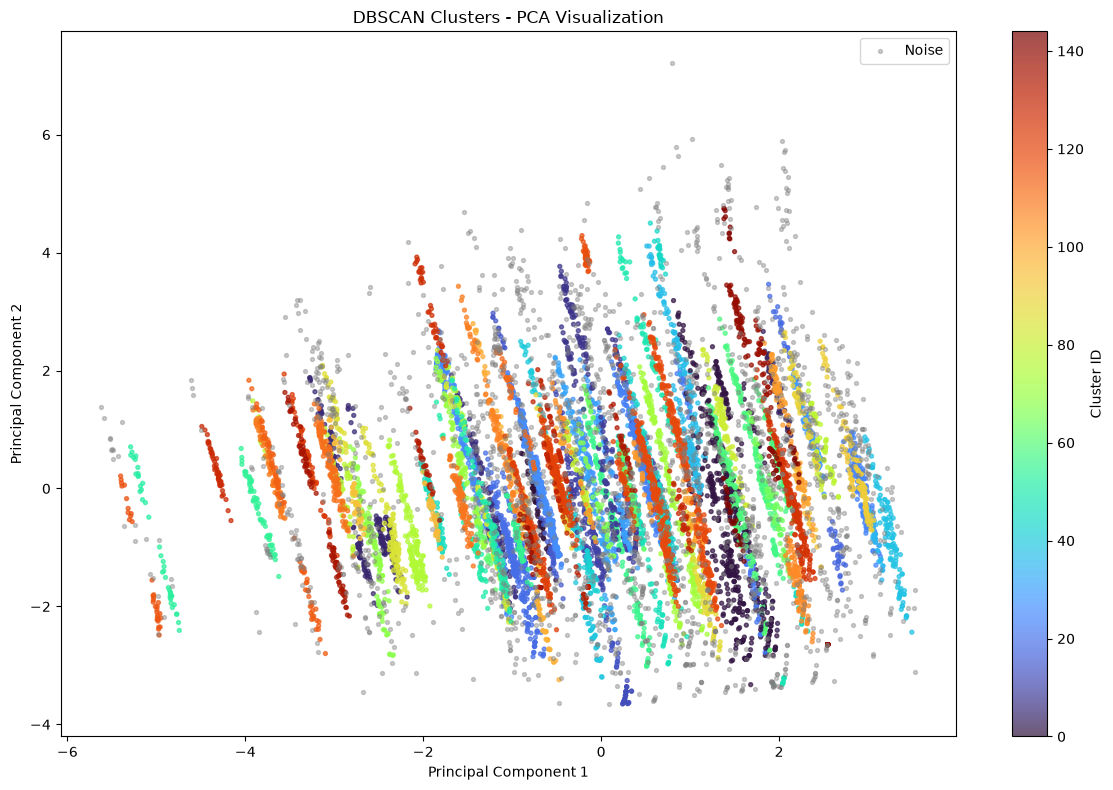

In [30]:

# Separate noise points from clustered observations
noise_mask = reference_labels == -1
cluster_mask = reference_labels != -1

plt.figure(figsize=(12, 8))

# Plot clustered fish
scatter = plt.scatter(
    X_pca[cluster_mask, 0],
    X_pca[cluster_mask, 1],
    c=reference_labels[cluster_mask],
    cmap="turbo",
    s=8,
    alpha=0.7
)

# Plot noise in gray
plt.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c="gray",
    s=8,
    alpha=0.4,
    label="Noise"
)

plt.title("DBSCAN Clusters - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.colorbar(scatter, label="Cluster ID")

plt.tight_layout()
plt.show()


In [31]:

# Create output directories
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../results", exist_ok=True)

# Export cleaned dataset with reference clusters
df.to_csv(
    "../data/processed/dataset_clean.csv",
    index=False
)

# Export DBSCAN grid search results
results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/results.csv",
    index=False
)

print("Export completed!")
print("Dataset shape:", df.shape)
print("Results shape:", results_df.shape)
print("\nResults columns:")
print(results_df.columns.tolist())


Export completed!
Dataset shape: (12288, 26)
Results shape: (12, 7)

Results columns:
['eps', 'min_samples', 'n_clusters', 'noise_percentage', 'silhouette', 'davies_bouldin', 'time_seconds']


In [32]:
print("Nombre de colonnes :", len(df.columns))
print("\nColonnes du dataset :")
print(df.columns.tolist())

print("\nColonne cluster présente :", "cluster" in df.columns)

Nombre de colonnes : 26

Colonnes du dataset :
['Code_ID', 'Stream', 'Location', 'Family', 'Genus', 'Species', 'Scientific_name', 'Length_mm', 'Mass_g', 'Lat_degree', 'Long_degree', 'Source', 'Day', 'Month', 'Year', 'Fish_number', 'SA_m2', 'TP_mg.l', 'TN_mg.l', 'Temp_degree_celcius', 'Prec_mm', 'Alt_m', 'IMPRESS', 'ln_length', 'ln_mass', 'condition_factor']

Colonne cluster présente : False


In [33]:
# Add reference DBSCAN labels to the dataset
df["cluster"] = reference_labels

# Export corrected dataset
df.to_csv(
    "../data/processed/dataset_clean.csv",
    index=False
)

print("Cluster column added successfully!")
print("\nDataset shape:", df.shape)
print("\nCluster distribution:")
print(df["cluster"].value_counts().sort_index())

print("\nNoise percentage:",
      round((df["cluster"] == -1).mean() * 100, 2), "%")

Cluster column added successfully!

Dataset shape: (12288, 27)

Cluster distribution:
cluster
-1      2066
 0        52
 1       576
 2        25
 3        52
        ... 
 140      50
 141      22
 142      11
 143      11
 144      26
Name: count, Length: 146, dtype: int64

Noise percentage: 16.81 %


In [34]:

# Add external validation metrics to all DBSCAN configurations

for result in results:
    model = DBSCAN(
        eps=result["eps"],
        min_samples=result["min_samples"],
        metric="euclidean"
    )

    labels = model.fit_predict(X_scaled)

    result["ARI_species"] = adjusted_rand_score(
        species, labels
    )

    result["NMI_species"] = normalized_mutual_info_score(
        species, labels
    )

# Recreate and export results table
results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/results.csv",
    index=False
)

print("Updated results.csv successfully!")
print("Shape:", results_df.shape)
display(results_df.round(4))


Updated results.csv successfully!
Shape: (12, 9)


,eps,min_samples,n_clusters,noise_percentage,silhouette,davies_bouldin,time_seconds,ARI_species,NMI_species
0,0.3,5,306,25.4883,0.2685,0.8986,1.8880,0.0175,0.3545
1,0.3,10,163,48.5677,0.4169,0.7508,1.7081,0.0048,0.3037
2,0.3,20,45,80.9163,0.6076,0.5299,1.7165,-0.0011,0.1627
3,0.5,5,179,8.0892,0.1010,1.2146,3.0483,0.0364,0.3495
4,0.5,10,145,16.8132,0.1943,1.1566,3.1196,0.0312,0.3416
5,0.5,20,99,39.1113,0.3130,1.0093,2.7471,0.0102,0.2973
6,0.8,5,77,2.3926,-0.0325,1.2170,5.5186,0.0437,0.2873
7,0.8,10,65,4.4189,-0.0099,1.2995,5.7179,0.0438,0.2805
8,0.8,20,63,9.3587,0.0118,1.1924,6.1212,0.0431,0.2799
9,1.2,5,24,0.6999,-0.1805,0.9519,9.4092,0.0142,0.1641
